# Exploring ANN Loss and Training Performance

### Neural Network Fundamentals and Training
*neural-network introduction and architecture, forward propagation, loss/cost functions, backpropagation, gradient descent variants,learning rate and iterations, practical experiments.*

**The network learns by adjusting its trainable parameters (weights and biases)**

**Forward pass:** Input data pass through the network from the input layer, through the hidden layers, to the output layer. Each neurion connection has an associated weight, which determines the influence of one neuron on another. During the **forward pass**, the current weights are used to calculate the network's prediction.

**Loss/cost function:** The output layer produces the predicted values. A loss function measures the difference between the predicted and actual values, indicating how well or poorly the network is currently performing.

**Backpropagation:** The error information is propagated backwards through the network. Backpropagation calculates the gradients that indicate how much each weight contributed to the loss and how changing it would affect the loss. The error helps faciliating the weights adjustment (back propagation of error). 

**Gradient descent:** Is used to determine the optimal weight by acting as a guide when seaerching for an oprimal value (local minimal) of a cost function. The calculated gradients are used by an optimisation algorithm (e.g. GDS), to determine the direction in which the weights should be adjusted to reduce the loss. The aim is to move towards a minimum of the loss function.

**Weight update:** After backpropagation, the weights are updated according to the gradients and **the learning rate**, which controls the size of each adjustment, helps determine the speed of the movement into the direction. Step size indicates how long it takes, how many steps, it takes to get there. The next forward pass then uses these updated weights.

Learning cycle: This process repeats during training: forward pass → calculate loss → backpropagation → calculate gradients → update weights → next forward pass.

* Backpropagation = Tells, how the weights shoul change by calculating how the loss relates to the network's weights (the gradients).
* Gradient descent = Performs updates, it uses those gradients to decide how to update the weights to reduce the loss. 

**Gradient Descents**
Gradient descent is an optimisation algorithm used to **minimise the loss function** by updating model weights in the direction indicated by **the gradients**.

- Batch Gradient Descent (BGD) – uses the entire training dataset to calculate the gradient before each weight update. This produces relatively stable and deterministic updates, but can be computationally expensive for large datasets.

- Stochastic Gradient Descent (SGD) – uses one randomly selected/shuffled training instance at a time. A single instance goes through the forward pass, the loss and gradients are calculated, and the weights are updated before processing the next instance. This produces frequent, noisy updates. The fluctuations can help the optimisation process move out of some local minima or saddle regions, but SGD does not guarantee finding the global minimum.

- Mini-batch Gradient Descent – divides the training data into small batches (e.g. 32, 64, 128 observations). The weights are updated after each mini-batch. It provides a compromise between the computational efficiency of batch processing and the noisier, more frequent updates of SGD. This is commonly used for training neural networks.

The GD variants differ in how much training data is used to calculate the gradient before each weight update.

- Batch GD: all observations → 1 update
- SGD: 1 observation → 1 update
- Mini-batch GD: small group of observations → 1 update

## Calculating cost with gradient descent and learning rate

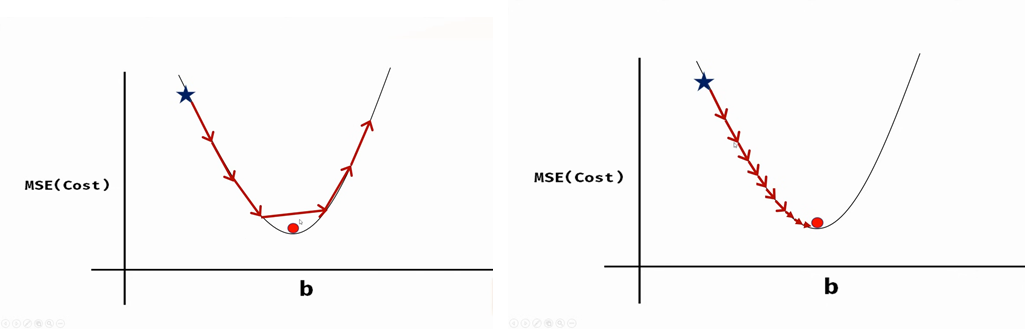

### Learning rate = size of each step
It controls how much the weights are changed after each gradient calculation

- **BIG learning rate:** making bigger weight adjustment, bigger steps but may miss the global minimum, costs fluctuate.
- **SMALL learning rate:** smaller adjustment/steps, costs descresing slowly and smoothly BUT training times takes longer.

### Iteration values

How many opportunities model needs to update, controlling the lenght of the optimisation process:

- **LOW iteration values:** if too low training may stop while cost is still decreasing.
- **HIGH iteration values:**  woth too many iterations, we may have reached the minimum but the training contonious with little additional improvement

#### Goal is to reach minimum cost with minimum iteration

Does the learning rate permits stable learning but number of iterations is insufficient for convergence?

- LR = 0.001, 100 iterations  → cost still decreasing
- LR = 0.001, 1000 iterations → much lower cost
- LR = 0.1, 100 iterations → cost jumps up and down (learning too high?)


Learning rate = how big are the steps?
Iterations = how many steps to take?
Cost curve = are the choices are allowing optimisation to converge?

## 1: Iteration = 100, Learning Rate = 0.08
cost jumping (learnig too high?)

In [6]:
# code credit:codebasics https://codebasics.io/coming-soon

import numpy as np

def gradient_descent(x,y):
    m_curr = b_curr = 0
    iterations = 100       #change value
    n = len(x)
    learning_rate = 0.8   #change value

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 49.6, b 14.4, cost 89.0 iteration 0
m -842.8800000000001, b -232.32000000000008, cost 28309.16 iteration 1
m 15156.544000000005, b 4199.616000000002, cost 9100322.830400003 iteration 2
m -271707.18720000016, b -75256.78080000004, cost 2925460639.117378 iteration 3
m 4871621.455360003, b 1349362.9670400007, cost 940441384323.9053 iteration 4
m -87345808.80076805, b -24193386.365952015, cost 302321619223209.2 iteration 5
m 1566068730.2493193, b 433775928.4632579, cost 9.718666465901837e+16 iteration 6
m -28078865329.162346, b -7777395447.874686, cost 3.1242382902728847e+19 iteration 7
m 503440662663.4935, b 139444990863.10406, cost 1.0043419978094176e+22 iteration 8
m -9026450956307.293, b -2500182175288.232, cost 3.2286360861280754e+24 iteration 9
m 161839960316134.22, b 44827073895462.35, cost 1.0379025271655006e+27 iteration 10
m -2901713295945998.0, b -803728053854707.2, cost 3.3365223802240554e+29 iteration 11
m 5.2026335371206216e+16, b 1.4410460652853628e+16, cost 1.072584496362

## 2: Iteration = 100, Learning Rate = 0.001
cost deacreasing gradually with enough iterations

In [ ]:
def gradient_descent(x,y):
    m_curr = b_curr = 0
    iterations = 100      
    n = len(x)
    learning_rate = 0.001   

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 0.062, b 0.018000000000000002, cost 89.0 iteration 0
m 0.122528, b 0.035592000000000006, cost 84.881304 iteration 1
m 0.181618832, b 0.052785648000000004, cost 80.955185108544 iteration 2
m 0.239306503808, b 0.069590363712, cost 77.21263768455901 iteration 3
m 0.29562421854195203, b 0.086015343961728, cost 73.64507722605434 iteration 4
m 0.35060439367025875, b 0.10206956796255283, cost 70.2443206760065 iteration 5
m 0.40427867960173774, b 0.11776180246460617, cost 67.00256764921804 iteration 6
m 0.4566779778357119, b 0.13310060678206653, cost 63.912382537082294 iteration 7
m 0.5078324586826338, b 0.14809433770148814, cost 60.966677449199324 iteration 8
m 0.5577715785654069, b 0.16275115427398937, cost 58.15869595270883 iteration 9
m 0.606524096911324, b 0.17707902249404894, cost 55.481997572035766 iteration 10
m 0.6541180926443106, b 0.1910857198675929, cost 52.9304430134884 iteration 11
m 0.7005809802869303, b 0.20477883987199186, cost 50.49818008081245 iteration 12
m 0.745939525681

## 3: Iteration = 1000, Learning Rate = 0.001
minimum improvement on costs, too many iterations

In [5]:
def gradient_descent(x,y):
    m_curr = b_curr = 0
    iterations = 1000      
    n = len(x)
    learning_rate = 0.001  

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 0.062, b 0.018000000000000002, cost 89.0 iteration 0
m 0.122528, b 0.035592000000000006, cost 84.881304 iteration 1
m 0.181618832, b 0.052785648000000004, cost 80.955185108544 iteration 2
m 0.239306503808, b 0.069590363712, cost 77.21263768455901 iteration 3
m 0.29562421854195203, b 0.086015343961728, cost 73.64507722605434 iteration 4
m 0.35060439367025875, b 0.10206956796255283, cost 70.2443206760065 iteration 5
m 0.40427867960173774, b 0.11776180246460617, cost 67.00256764921804 iteration 6
m 0.4566779778357119, b 0.13310060678206653, cost 63.912382537082294 iteration 7
m 0.5078324586826338, b 0.14809433770148814, cost 60.966677449199324 iteration 8
m 0.5577715785654069, b 0.16275115427398937, cost 58.15869595270883 iteration 9
m 0.606524096911324, b 0.17707902249404894, cost 55.481997572035766 iteration 10
m 0.6541180926443106, b 0.1910857198675929, cost 52.9304430134884 iteration 11
m 0.7005809802869303, b 0.20477883987199186, cost 50.49818008081245 iteration 12
m 0.745939525681

## 4: Iteration = 10, Learning Rate = 0.001
Too little iteration, costs still decreasing

In [ ]:
def gradient_descent(x,y):
    m_curr = b_curr = 0
    iterations = 10      
    n = len(x)
    learning_rate = 0.001   

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 0.062, b 0.018000000000000002, cost 89.0 iteration 0
m 0.122528, b 0.035592000000000006, cost 84.881304 iteration 1
m 0.181618832, b 0.052785648000000004, cost 80.955185108544 iteration 2
m 0.239306503808, b 0.069590363712, cost 77.21263768455901 iteration 3
m 0.29562421854195203, b 0.086015343961728, cost 73.64507722605434 iteration 4
m 0.35060439367025875, b 0.10206956796255283, cost 70.2443206760065 iteration 5
m 0.40427867960173774, b 0.11776180246460617, cost 67.00256764921804 iteration 6
m 0.4566779778357119, b 0.13310060678206653, cost 63.912382537082294 iteration 7
m 0.5078324586826338, b 0.14809433770148814, cost 60.966677449199324 iteration 8
m 0.5577715785654069, b 0.16275115427398937, cost 58.15869595270883 iteration 9


## 5: Iteration = 100, Learning Rate = 0.1
Cost jumping, too big steps? too little iterations?

In [7]:
def gradient_descent(x,y):
    m_curr = b_curr = 0
    iterations = 100     
    n = len(x)
    learning_rate = 0.1   

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

gradient_descent(x,y)

m 6.2, b 1.8, cost 89.0 iteration 0
m -2.320000000000001, b -0.4800000000000002, cost 165.24 iteration 1
m 9.272000000000002, b 2.8080000000000007, cost 307.59840000000014 iteration 2
m -6.611200000000007, b -1.5168000000000017, cost 573.3613440000004 iteration 3
m 15.043520000000012, b 4.5532800000000035, cost 1069.4523110400019 iteration 4
m -14.584192000000016, b -3.5834880000000053, cost 1995.4416651264037 iteration 5
m 25.851123200000032, b 7.6837248000000065, cost 3723.822955597831 iteration 6
m -29.431582720000037, b -7.563694080000013, cost 6949.846718357686 iteration 7
m 46.056115712000064, b 13.407994368000011, cost 12971.181693567853 iteration 8
m -57.11213547520009, b -15.10727393280003, cost 24209.895819923568 iteration 9
m 83.79892692992013, b 23.981462138880037, cost 45186.721312913374 iteration 10
m -108.74758959923219, b -29.294186446848048, cost 84339.4971995226 iteration 11
m 154.27361938718752, b 43.61320460206089, cost 157417.24894304306 iteration 12
m -205.0962660